# code_047 · Missingness and observation processes

**Book:** section 10.1. A self-contained data-cleaning laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_10_GUIDE.md), [run evidence](../CHAPTER_10_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_047).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Construction audits are distinct from predictive assessment; fitted examples declare training/development/final roles locally. All data and calibration/measurement assumptions are simulated, without field safety, causal or universal cleaning claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=1047;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 1047


<a id="states"></a>
## One NaN can hide different evidence

Keep a status column: absent record, sensor structurally not installed, failed instrument, or a value censored below a detection limit. A below-limit value supplies an inequality, not an ordinary missing draw. The toy model below studies dropout of one sensor input only; it is not a censored-data estimator. Six hundred independent members have observed load L~Uniform(0,1), latent sensor x=.3+2L+Normal(0,.3) mm, and later target y=1+.7x+.2L+Normal(0,.15) mm. Split 300/150/150 members for train/development/final before inspection.

Dropout probabilities are specified by the author: MCAR .25; MAR .05+.5L depends only on recorded load; MNAR .1+.6*sigmoid(4*(x-1.6)) depends on the value missing from the observed table. These labels describe assumptions relative to the recorded variables, not diagnoses learned from an observed missingness pattern. The latent x remains visible to the simulator author for checking, never to the fitted missing-input procedure.


In [2]:
from scipy.special import expit
states=pd.DataFrame({'state':['absent','structural_unavailability','instrument_failure','left_censored'],'stored_value':[np.nan]*4,'known_bound_mm':[np.nan,np.nan,np.nan,.15]})
assert states.state.nunique()==4 and states.stored_value.isna().all() and states.loc[3,'known_bound_mm']==.15
N=600;load=rng.uniform(0,1,N);latent=.3+2*load+rng.normal(0,.3,N);y=1+.7*latent+.2*load+rng.normal(0,.15,N)
tr=np.arange(300);dv=np.arange(300,450);te=np.arange(450,600)
prob={'MCAR':np.full(N,.25),'MAR':.05+.5*load,'MNAR':.1+.6*expit(4*(latent-1.6))}
missing={k:rng.random(N)<v for k,v in prob.items()};observed={k:np.where(missing[k],np.nan,latent) for k in prob}
assert all(np.isnan(observed[k]).sum()==missing[k].sum() for k in prob)
assert not set(tr)&set(te) and np.allclose(prob['MCAR'],.25)
assert np.allclose(prob['MAR'],.05+.5*load) and np.all((prob['MNAR']>=.1)&(prob['MNAR']<=.7))
RESULTS['status_fixture']=states.state.tolist();RESULTS['dropout_fraction']={k:float(v.mean()) for k,v in missing.items()};RESULTS['observed_training_means_mm']={k:float(np.nanmean(v[tr])) for k,v in observed.items()};RESULTS['latent_training_mean_mm']=float(latent[tr].mean())


<a id="mechanisms"></a>
## Diagram generator inputs, not an inferred causal graph

Each panel names which generated value controls the dropout probability R=1. MCAR uses only a fixed coin; MAR also uses observed load; MNAR uses latent x that is not available when R=1. Load is associated with x, so marginal dropout-versus-load plots alone cannot establish which mechanism produced real data. The arrows below describe stipulated computational inputs to the simulation.


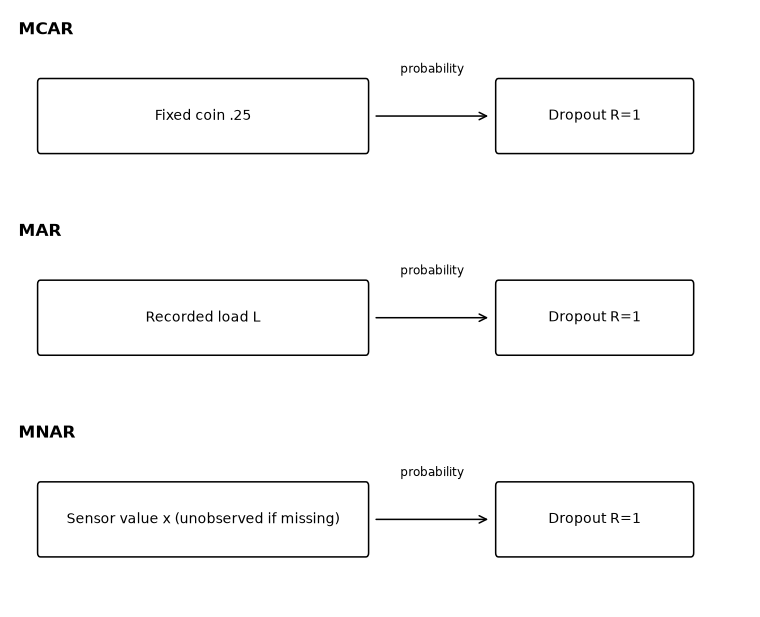

In [3]:
from matplotlib.patches import FancyBboxPatch,FancyArrowPatch
fig,axes=plt.subplots(3,1,figsize=(6.8,5.5))
for ax,name,source in zip(axes,['MCAR','MAR','MNAR'],['Fixed coin .25','Recorded load L','Sensor value x (unobserved if missing)']):
 ax.axis('off');ax.set(xlim=(0,10),ylim=(0,2));ax.text(.1,1.75,name,weight='bold',fontsize=11)
 for x0,w,label in [(2.6,4.4,source),(7.9,2.6,'Dropout R=1')]:
  ax.add_patch(FancyBboxPatch((x0-w/2,.55),w,.7,boxstyle='round,pad=.04',fc='white',ec='black'));ax.text(x0,.9,label,ha='center',va='center',fontsize=9)
 ax.add_patch(FancyArrowPatch((4.9,.9),(6.5,.9),arrowstyle='->',mutation_scale=12));ax.text(5.7,1.35,'probability',ha='center',fontsize=8)
plt.show()


<a id="fit"></a>
## Fit the repair inside training, then select only on development

For each mechanism compare two fixed OLS designs: [1,L,median-filled x] and the same columns plus an observed missingness indicator. Each median uses observed training inputs only; indicator R is available at prediction. Both rules see the same role assignments and labels. Select the lower development MSE, with first-candidate tie breaking. This tests the disclosed predictive repair, not recovery of the latent distribution or valid population inference under arbitrary MNAR.


In [4]:
models={};features={};medians={};dev={};selected={}
for k in prob:
 medians[k]=float(np.nanmedian(observed[k][tr]));filled=np.where(missing[k],medians[k],observed[k]);base=np.column_stack([np.ones(N),load,filled]);features[k]={'median':base,'median_indicator':np.column_stack([base,missing[k].astype(float)])}
 assert np.isclose(medians[k],np.median(latent[tr][~missing[k][tr]]))
 models[k]={name:np.linalg.lstsq(X[tr],y[tr],rcond=None)[0] for name,X in features[k].items()}
 dev[k]={name:float(np.mean((features[k][name][dv]@coef-y[dv])**2)) for name,coef in models[k].items()};selected[k]=min(dev[k],key=dev[k].get)
 assert all(np.isfinite(list(dev[k].values()))) and np.isfinite(filled).all()
RESULTS['training_medians_mm']=medians;RESULTS['development_MSE_mm2']=dev;RESULTS['selected_policy']=selected


<a id="final"></a>
## Assess frozen repairs on independent final members

Report every predeclared method on the final role once; do not choose a new winner or median from it. The selected policy is already frozen by development. A missingness indicator may carry useful information about the acquisition process, but its meaning can change if sensor failure policy changes at deployment. Lower error here does not identify or make MNAR ignorable.


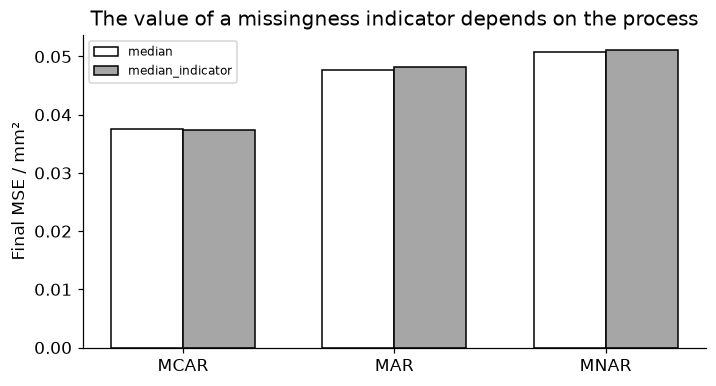

In [5]:
final={k:{name:float(np.mean((features[k][name][te]@coef-y[te])**2)) for name,coef in models[k].items()} for k in prob}
assert all(np.isfinite(list(v.values())).all() for v in final.values())
fig,ax=plt.subplots(figsize=(6.4,3.4));xx=np.arange(3);w=.34
for j,(name,shade) in enumerate([('median','white'),('median_indicator','.65')]):ax.bar(xx+(j-.5)*w,[final[k][name] for k in prob],w,color=shade,edgecolor='black',label=name)
ax.set(xticks=xx,xticklabels=list(prob),ylabel='Final MSE / mm²',title='The value of a missingness indicator depends on the process');ax.legend(fontsize=8);plt.show()
RESULTS['final_MSE_mm2']=final;RESULTS['selected_final_MSE_mm2']={k:final[k][selected[k]] for k in prob}


<a id="exercises"></a>
## Exercises and hints

1. Change dropout at deployment while keeping the physical response law fixed. Preserve new final cases.
2. Treat all four status fixtures as ordinary missing values and describe what information is erased.
3. Replace a left-censored reading with zero or a midpoint; state the extra assumption each makes.
4. Add an always-observed predictor explaining dropout and specify what MAR is conditional on.

**Hints:** observed data generally cannot certify an MNAR mechanism or the unseen values. Single imputation suppresses uncertainty; prediction and population inference have different goals. See [Rubin's original missing-data formulation](https://doi.org/10.1093/biomet/63.3.581) and official [imputation documentation](https://scikit-learn.org/1.9/modules/impute.html). No multiple-imputation or censoring estimator is implemented here.


In [6]:
summary={'example_id':'code_047','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['absent censored structural and failed measurements', 'MCAR MAR and MNAR as generator assumptions', 'training-only imputation and missingness indicators', 'development-only policy selection', 'protected final comparison without identifying missingness from data'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["absent censored structural and failed measurements", "MCAR MAR and MNAR as generator assumptions", "training-only imputation and missingness indicators", "development-only policy selection", "protected final comparison without identifying missingness from data"], "elapsed_seconds": 0.114, "example_id": "code_047", "hardware": "Darwin arm64 CPU", "results": {"development_MSE_mm2": {"MAR": {"median": 0.05686473232579734, "median_indicator": 0.05455313085636703}, "MCAR": {"median": 0.04581673660218361, "median_indicator": 0.04574351574907466}, "MNAR": {"median": 0.051527498096929816, "median_indicator": 0.04851179152247709}}, "dropout_fraction": {"MAR": 0.3233333333333333, "MCAR": 0.22666666666666666, "MNAR": 0.30666666666666664}, "final_MSE_mm2": {"MAR": {"median": 0.04767742690274684, "median_indicator": 0.04823922372614488}, "MCAR": {"median": 0.03755836232001528, "median_indicator": 0.037406609880808746}, "MNAR": {"median": 0.05069006